In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import linear_model
import joblib

In [3]:
data = pd.read_csv("telecom_customer_churn.csv")
zipcode = pd.read_csv("telecom_zipcode_population.csv")

In [4]:
data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [5]:
zipcode.head()

,Zip Code,Population
0,90001,54492
1,90002,44586
2,90003,58198
3,90004,67852
4,90005,43019


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

In [7]:
print(data["Customer Status"].count().sum())
print(data["Customer Status"].unique())
print(data['Customer Status'].value_counts())

7043
<StringArray>
['Stayed', 'Churned', 'Joined']
Length: 3, dtype: str
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


In [8]:
data["Offer"].value_counts()

Offer
Offer B    824
Offer E    805
Offer D    602
Offer A    520
Offer C    415
Name: count, dtype: int64

In [9]:
data = data.merge(zipcode, on='Zip Code', how='left')
data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason,Population
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN,4498
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN,31297
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices,62069
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction,46677
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability,42853


In [10]:
droped = ['Customer ID','Longitude','Latitude','Zip Code','Total Charges','Total Refunds','Total Extra Data Charges','Total Long Distance Charges']

In [11]:
data.drop(droped,axis=1,inplace=True)

In [12]:
data.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Customer Status,Churn Category,Churn Reason,Population
0,Female,37,Yes,0,Frazier Park,2,9,NaN,Yes,42.39,...,Yes,One Year,Yes,Credit Card,65.6,974.81,Stayed,NaN,NaN,4498
1,Male,46,No,0,Glendale,0,9,NaN,Yes,10.69,...,No,Month-to-Month,No,Credit Card,-4.0,610.28,Stayed,NaN,NaN,31297
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,415.45,Churned,Competitor,Competitor had better devices,62069
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1599.51,Churned,Dissatisfaction,Product dissatisfaction,46677
4,Female,75,Yes,0,Camarillo,3,3,NaN,Yes,7.38,...,Yes,Month-to-Month,Yes,Credit Card,83.9,289.54,Churned,Dissatisfaction,Network reliability,42853


In [13]:
x = data.drop(columns=['Customer Status'])
x.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Churn Category,Churn Reason,Population
0,Female,37,Yes,0,Frazier Park,2,9,NaN,Yes,42.39,...,No,Yes,One Year,Yes,Credit Card,65.6,974.81,NaN,NaN,4498
1,Male,46,No,0,Glendale,0,9,NaN,Yes,10.69,...,Yes,No,Month-to-Month,No,Credit Card,-4.0,610.28,NaN,NaN,31297
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,415.45,Competitor,Competitor had better devices,62069
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1599.51,Dissatisfaction,Product dissatisfaction,46677
4,Female,75,Yes,0,Camarillo,3,3,NaN,Yes,7.38,...,No,Yes,Month-to-Month,Yes,Credit Card,83.9,289.54,Dissatisfaction,Network reliability,42853


In [14]:
y = data["Customer Status"]
y.head()

0     Stayed
1     Stayed
2    Churned
3    Churned
4    Churned
Name: Customer Status, dtype: str

<Axes: xlabel='Gender', ylabel='Count'>

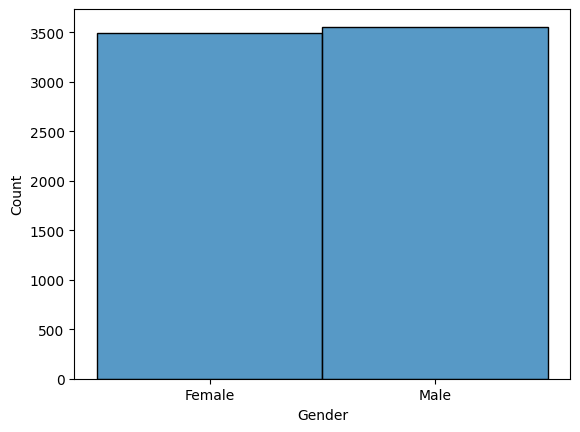

In [15]:
sns.histplot(x['Gender']) # More Male users as customers

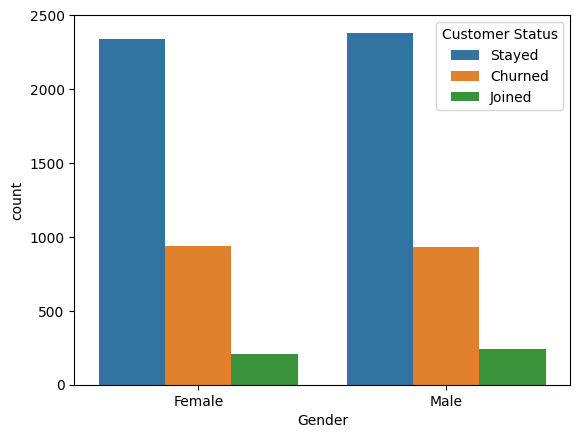

In [16]:
sns.countplot(data=data, x='Gender', hue='Customer Status')
plt.savefig('Gender and Customer Relationship.png')
# No gender wise relationship for churn reasons,joined and stayed. There are equal distributed.

<Axes: >

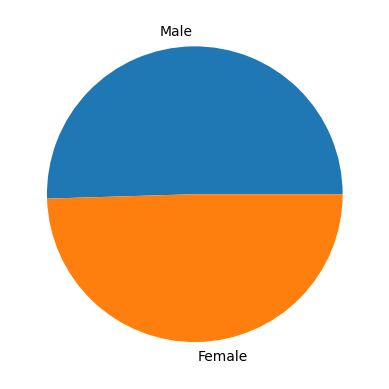

In [17]:
data['Gender'].value_counts().plot.pie() # Equal Importances of Gender as user

<Axes: xlabel='Customer Status', ylabel='Gender'>

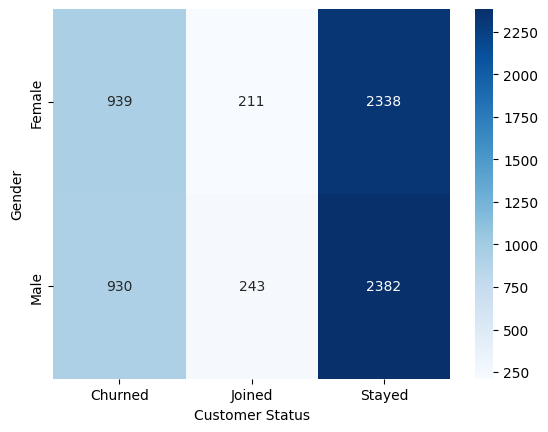

In [18]:
s = pd.crosstab(data['Gender'], data['Customer Status'])
sns.heatmap(s,annot=True, fmt='d', cmap='Blues')

In [19]:
pd.crosstab(data['Gender'], data['Customer Status']) # Mostly female churned , male joined and Stayed are more over equal

Customer Status,Churned,Joined,Stayed
Gender,,,
Female,939,211,2338
Male,930,243,2382


In [20]:
gen = pd.get_dummies(x['Gender'],drop_first=True,dtype='uint8')
gen.head()

,Male
0,0
1,1
2,1
3,1
4,0


count    7043.000000
mean       46.509726
std        16.750352
min        19.000000
25%        32.000000
50%        46.000000
75%        60.000000
max        80.000000
Name: Age, dtype: float64


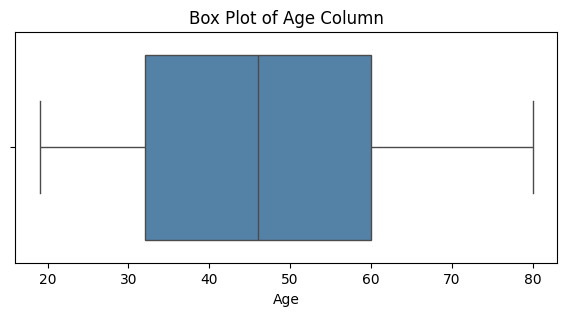

In [21]:
# Print exact summary stats (min, 25%, 50% median, 75%, max)
print(x['Age'].describe())

# Plot the single column
plt.figure(figsize=(7, 3))
sns.boxplot(x=x['Age'], color='steelblue')
plt.title('Box Plot of Age Column')
plt.xlabel('Age')
plt.show()
# mostly 30 to 60 user are exist

<Axes: xlabel='Age', ylabel='Count'>

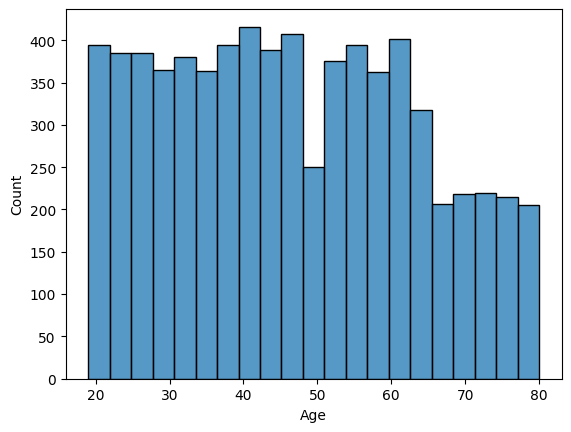

In [22]:
sns.histplot(x['Age']) # 35 to 60 age of users are exists more

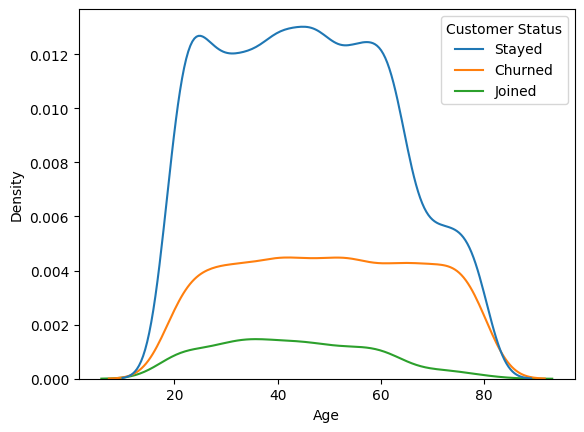

In [23]:
sns.kdeplot(data=data, x='Age',hue='Customer Status')
plt.savefig('Age_distribution_with_Customer_Status')
# from age 30 to 60 are stayed and 60 to 80 are high churn risk

In [24]:
x['Age'].skew()

np.float64(0.1621864486741778)

In [25]:
x['Age'] = x['Age'].astype('uint8')
x['Age'].dtype

dtype('uint8')

<Axes: xlabel='Married', ylabel='count'>

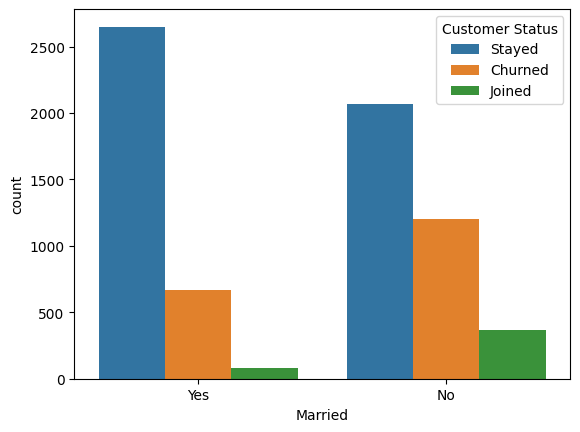

In [26]:
sns.countplot(data=data, x='Married', hue='Customer Status') # More stayed are married and more churned are not married

In [27]:
pd.crosstab(data['Married'], data['Customer Status']) # Same values as countplot shows. Joined are not married

Customer Status,Churned,Joined,Stayed
Married,,,
No,1200,370,2071
Yes,669,84,2649


<Axes: xlabel='Customer Status', ylabel='Married'>

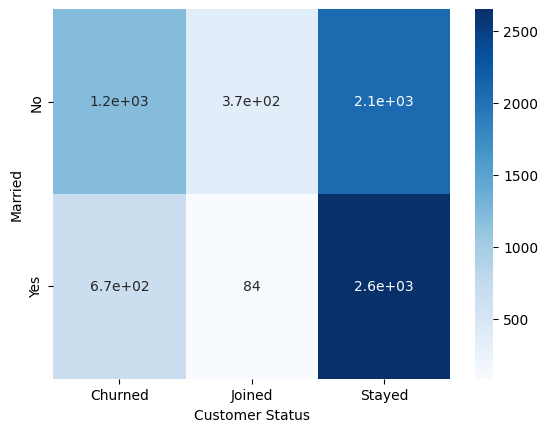

In [28]:
a = pd.crosstab(data['Married'], data['Customer Status'])
sns.heatmap(a,annot=True,cmap='Blues')

In [29]:
mar = pd.get_dummies(x['Married'],drop_first=True,dtype='uint8')
mar.head()

,Yes
0,1
1,0
2,0
3,1
4,1


<Axes: xlabel='Number of Dependents', ylabel='Count'>

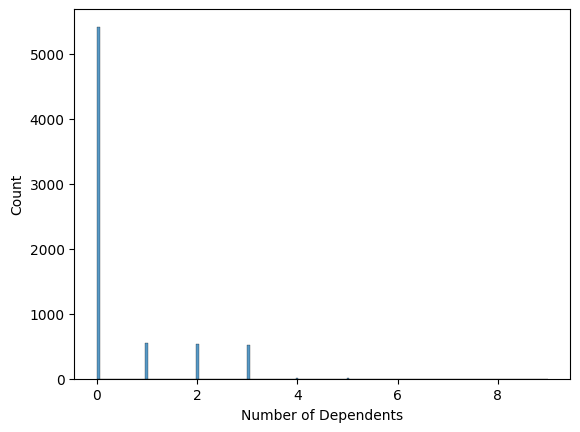

In [30]:
sns.histplot(data=data,x='Number of Dependents') # Mostly no Dependents

<Axes: xlabel='Number of Dependents', ylabel='count'>

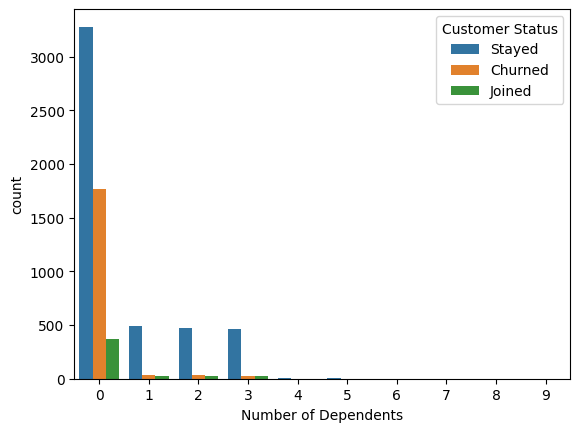

In [31]:
sns.countplot(data=data,x='Number of Dependents',hue='Customer Status') # if stayed high no dependent,moderate churn.
# if 1 to 3 dependent

<Axes: ylabel='Number of Dependents'>

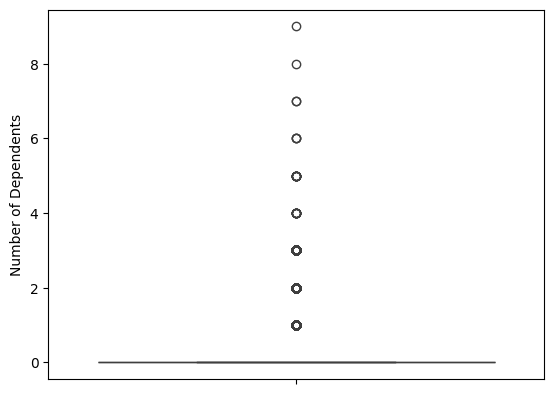

In [32]:
sns.boxplot(x['Number of Dependents']) # these are not outliers but real values

In [33]:
df = data[data['Customer Status'] != 'Joined'].copy()
df['Churn'] = (df['Customer Status'] == 'Churned').astype(int)

df['Has Dependents'] = (df['Number of Dependents'] > 0).map({True: 'Yes', False: 'No'})

print("Average dependents by Married:")
print(df.groupby('Married')['Number of Dependents'].mean().round(2))

print("\nCounts (Married vs Has Dependents):")
print(pd.crosstab(df['Married'], df['Has Dependents']))

print("\nRow percentages:")
print(pd.crosstab(df['Married'], df['Has Dependents'], normalize='index').round(2) * 100)

print("\nChurn rate (%) by Married and Has Dependents:")
print((df.groupby(['Married', 'Has Dependents'])['Churn'].mean() * 100).round(1))

Average dependents by Married:
Married
No     0.16
Yes    0.79
Name: Number of Dependents, dtype: float64

Counts (Married vs Has Dependents):
Has Dependents    No   Yes
Married                   
No              3011   260
Yes             2031  1287

Row percentages:
Has Dependents    No   Yes
Married                   
No              92.0   8.0
Yes             61.0  39.0

Churn rate (%) by Married and Has Dependents:
Married  Has Dependents
No       No                38.2
         Yes               19.2
Yes      No                30.2
         Yes                4.4
Name: Churn, dtype: float64


In [34]:
mar['Yes'].corr(x['Number of Dependents'])

np.float64(0.3242051367512027)

In [35]:
x['Number of Dependents'] = x['Number of Dependents'].astype('uint8')
x['Number of Dependents'].dtype

dtype('uint8')

In [36]:
x['City'].isna().sum()

np.int64(0)

In [37]:
x.drop(['City'],axis=1,inplace=True)

In [38]:
# Average Population for churned vs stayed (Joined customers excluded)
df = data[data['Customer Status'] != 'Joined']

print(df.groupby('Customer Status')['Population'].mean().round(0))

Customer Status
Churned    23957.0
Stayed     21388.0
Name: Population, dtype: float64


In [39]:
x['Number of Referrals'].skew()

np.float64(1.4460596247412694)

In [40]:
x['Number of Referrals'] = x['Number of Referrals'].astype('uint8')

<Axes: ylabel='Tenure in Months'>

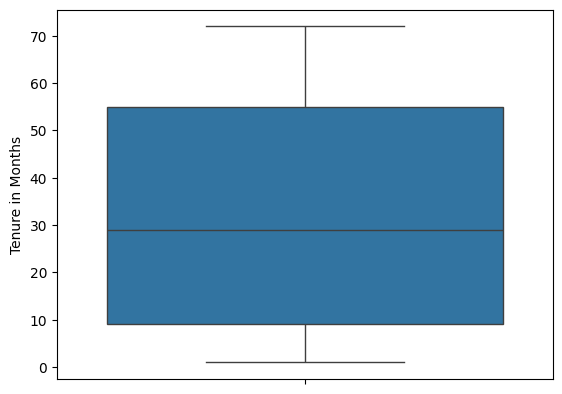

In [41]:
sns.boxplot(x['Tenure in Months'])

In [42]:
x['Tenure in Months'] = x['Tenure in Months'].astype('uint8')

In [43]:
x['Offer'].value_counts(dropna=0)

Offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

In [44]:
x['Offer'] = x['Offer'].fillna("No offer",axis=0)
x['Offer'].unique()

<StringArray>
['No offer', 'Offer E', 'Offer D', 'Offer A', 'Offer B', 'Offer C']
Length: 6, dtype: str

<Axes: ylabel='Offer'>

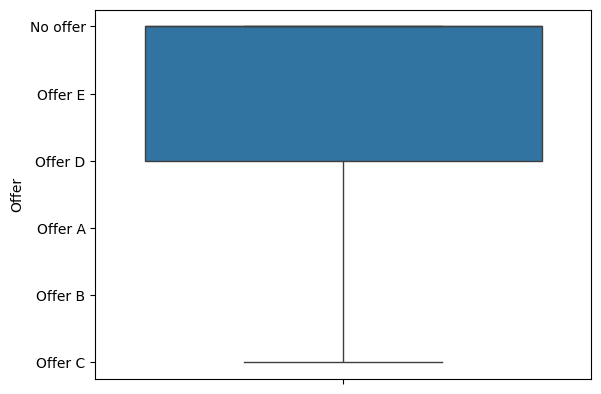

In [45]:
sns.boxplot(x["Offer"])

In [46]:
off = pd.get_dummies(x["Offer"],drop_first=True,dtype='uint8')
off.head()

,Offer A,Offer B,Offer C,Offer D,Offer E
0,0,0,0,0,0
1,0,0,0,0,0
2,0,0,0,0,1
3,0,0,0,1,0
4,0,0,0,0,0


In [47]:
x['Phone Service'] = x['Phone Service'].map({'Yes':1 , 'No':0})
x['Phone Service'].head()

0    1
1    1
2    1
3    1
4    1
Name: Phone Service, dtype: int64

In [48]:
x['Phone Service'] = x['Phone Service'].astype('uint8')
x['Phone Service'].head()

0    1
1    1
2    1
3    1
4    1
Name: Phone Service, dtype: uint8

<Axes: ylabel='Avg Monthly Long Distance Charges'>

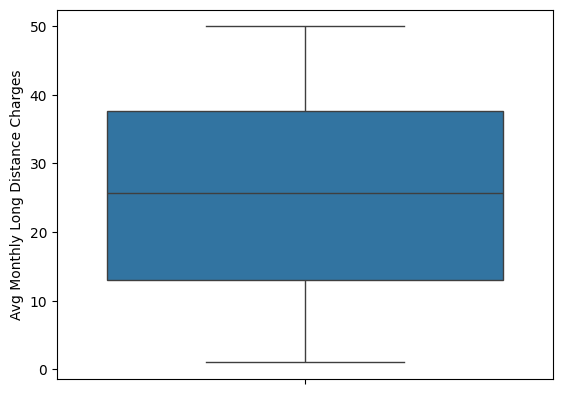

In [49]:
sns.boxplot(x['Avg Monthly Long Distance Charges'])

In [50]:
x['Avg Monthly Long Distance Charges'] = x['Avg Monthly Long Distance Charges'].fillna(0)

In [51]:
x['Avg Monthly Long Distance Charges']=x['Avg Monthly Long Distance Charges'].astype('float32')
x['Avg Monthly Long Distance Charges'].dtype

dtype('float32')

In [52]:
x['Multiple Lines'] = x['Multiple Lines'].fillna('No phones',axis=0)
x['Multiple Lines'].unique()

<StringArray>
['No', 'Yes', 'No phones']
Length: 3, dtype: str

In [53]:
mul = pd.get_dummies(x['Multiple Lines'],drop_first=True,dtype='uint8')
mul.head()

,No phones,Yes
0,0,0
1,0,1
2,0,0
3,0,0
4,0,0


In [54]:
x['Internet Service'] = x['Internet Service'].map({"Yes":1,"No":0}).astype('uint8')
x['Internet Service'].dtype

dtype('uint8')

In [55]:
x["Internet Type"] = x["Internet Type"].fillna('No Internet')
x["Internet Type"].unique()

<StringArray>
['Cable', 'Fiber Optic', 'DSL', 'No Internet']
Length: 4, dtype: str

In [56]:
inty = pd.get_dummies(x["Internet Type"],drop_first=True,dtype='uint8')
inty["No Internet"].dtype
inty["No Internet"].head()

0    0
1    0
2    0
3    0
4    0
Name: No Internet, dtype: uint8

In [57]:
x['Avg Monthly GB Download'] = x['Avg Monthly GB Download'].fillna(0)
col = 'Avg Monthly GB Download'

# 1. No blanks left? (should print 0)
print("Blanks:", x[col].isna().sum())

# 2. Any value with decimals? (should print 0)
print("With decimals:", (x[col] != x[col].round()).sum())

# 3. Inside the uint8 range of 0 to 255? (should print 0 and a max below 255)
print("Below 0:", (x[col] < 0).sum())
print("Max value:", x[col].max())

Blanks: 0
With decimals: 0
Below 0: 0
Max value: 85.0


In [58]:
x['Avg Monthly GB Download'] = x['Avg Monthly GB Download'].astype('uint8')
x['Avg Monthly GB Download'].dtype

dtype('uint8')

In [59]:
x['Online Security'] = x['Online Security'].fillna("No Service")
onse = pd.get_dummies(x['Online Security'],drop_first=True,dtype='uint8')
onse['Yes'].head()

0    0
1    0
2    0
3    0
4    0
Name: Yes, dtype: uint8

In [60]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

In [61]:
x['Online Backup'] = x['Online Backup'].fillna("No Service")
onbp = pd.get_dummies(x['Online Backup'],drop_first=True,dtype='uint8')

In [62]:
onbp.drop('No Service',inplace=True,axis=1)
onbp

,Yes
0,1
1,0
2,0
3,1
4,0
...,...
7038,0
7039,0
7040,1
7041,0


In [63]:
x['Device Protection Plan'] = x['Device Protection Plan'].fillna("No Service")
dpp = pd.get_dummies(x['Device Protection Plan'],drop_first=True,dtype='uint8')
dpp.drop('No Service',inplace=True,axis=1)
dpp

,Yes
0,0
1,0
2,1
3,1
4,0
...,...
7038,0
7039,0
7040,0
7041,1


In [64]:
x['Premium Tech Support'] = x['Premium Tech Support'].fillna("No Service")
pts = pd.get_dummies(x['Premium Tech Support'],drop_first=True,dtype='uint8')
pts.drop('No Service',inplace=True,axis=1)
pts

,Yes
0,1
1,0
2,0
3,0
4,1
...,...
7038,1
7039,0
7040,0
7041,1


In [65]:
x['Streaming TV'] = x['Streaming TV'].fillna("No Service")
stv = pd.get_dummies(x['Streaming TV'],drop_first=True,dtype='uint8')
stv.drop('No Service',inplace=True,axis=1)
stv

,Yes
0,1
1,0
2,0
3,1
4,1
...,...
7038,0
7039,0
7040,0
7041,0


In [66]:
x['Streaming Movies'] = x['Streaming Movies'].fillna("No Service")
smo = pd.get_dummies(x['Streaming Movies'],drop_first=True,dtype='uint8')
smo.drop('No Service',inplace=True,axis=1)
smo

,Yes
0,0
1,1
2,0
3,1
4,0
...,...
7038,0
7039,1
7040,0
7041,1


In [67]:
x['Streaming Music'] = x['Streaming Music'].fillna("No Service")
sm = pd.get_dummies(x['Streaming Music'],drop_first=True,dtype='uint8')
sm.drop('No Service',inplace=True,axis=1)
sm

,Yes
0,0
1,1
2,0
3,0
4,0
...,...
7038,1
7039,1
7040,0
7041,1


In [68]:
x['Unlimited Data'] = x['Unlimited Data'].fillna("No Service")
um = pd.get_dummies(x['Unlimited Data'],drop_first=True,dtype='uint8')
um.drop('No Service',inplace=True,axis=1)
um

,Yes
0,1
1,0
2,1
3,1
4,1
...,...
7038,1
7039,1
7040,1
7041,1


In [69]:
con = pd.get_dummies(x['Contract'],drop_first=True,dtype='uint8')
con

,One Year,Two Year
0,1,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
7038,1,0
7039,0,0
7040,0,0
7041,0,1


In [70]:
pabi = pd.get_dummies(x['Paperless Billing'],drop_first=1,dtype='uint8')
pabi

,Yes
0,1
1,0
2,1
3,1
4,1
...,...
7038,0
7039,1
7040,1
7041,0


In [71]:
pame = pd.get_dummies(x['Payment Method'],drop_first=1,dtype='uint8')
pame

,Credit Card,Mailed Check
0,1,0
1,1,0
2,0,0
3,0,0
4,1,0
...,...,...
7038,1,0
7039,0,0
7040,1,0
7041,1,0


In [72]:
x['Monthly Charge'] = x['Monthly Charge'].astype('float32')

<Axes: ylabel='Total Revenue'>

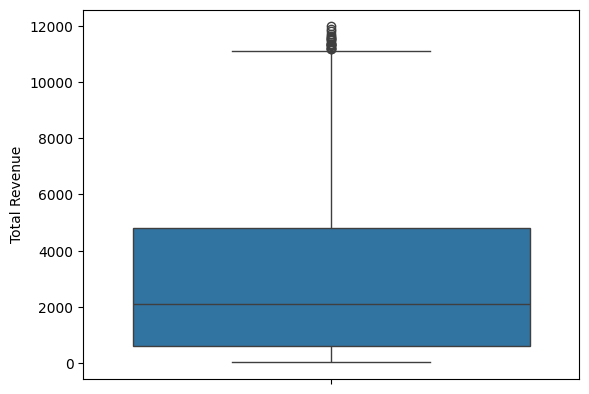

In [73]:
sns.boxplot(x['Total Revenue'])

In [74]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

In [75]:
x.drop(['Churn Category','Churn Reason'],axis=1,inplace=True)
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 27 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

<Axes: ylabel='Population'>

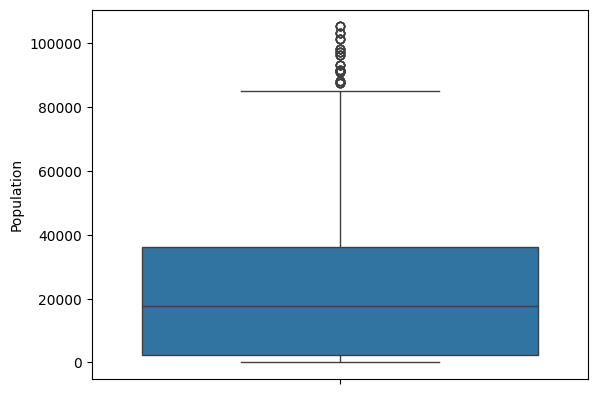

In [76]:
sns.boxplot(x['Population'])

In [77]:
x.describe()

,Age,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,Monthly Charge,Total Revenue,Population
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,1.951867,32.386767,0.903166,22.958954,0.783331,20.515405,63.596134,3034.379056,22139.603294
std,16.750352,0.962802,3.001199,24.542061,0.295752,15.448113,0.412004,20.418940,31.204744,2865.204542,21152.392837
min,19.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,-10.000000,21.360000,11.000000
25%,32.000000,0.000000,0.000000,9.000000,1.000000,9.210000,1.000000,3.000000,30.400000,605.610000,2344.000000
50%,46.000000,0.000000,0.000000,29.000000,1.000000,22.889999,1.000000,17.000000,70.050003,2108.640000,17554.000000
75%,60.000000,0.000000,3.000000,55.000000,1.000000,36.395000,1.000000,27.000000,89.750000,4801.145000,36125.000000
max,80.000000,9.000000,11.000000,72.000000,1.000000,49.990002,1.000000,85.000000,118.750000,11979.340000,105285.000000


In [78]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 27 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

In [79]:
gen.columns = ['Gender Yes']
print(x['Gender'])
x['Gender'] = gen
x['Gender']

0       Female
1         Male
2         Male
3         Male
4       Female
         ...  
7038    Female
7039      Male
7040      Male
7041      Male
7042      Male
Name: Gender, Length: 7043, dtype: str


0       0
1       1
2       1
3       1
4       0
       ..
7038    0
7039    1
7040    1
7041    1
7042    1
Name: Gender, Length: 7043, dtype: uint8

In [80]:
mar.columns = ['Marriage Yes']
print(x['Married'])
x['Married'] = mar
x['Married']

0       Yes
1        No
2        No
3       Yes
4       Yes
       ... 
7038     No
7039    Yes
7040     No
7041    Yes
7042    Yes
Name: Married, Length: 7043, dtype: str


0       1
1       0
2       0
3       1
4       1
       ..
7038    0
7039    1
7040    0
7041    1
7042    1
Name: Married, Length: 7043, dtype: uint8

In [81]:
x.drop('Offer',axis=1,inplace=True)
x = pd.concat([x,off],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,...,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Population,Offer A,Offer B,Offer C,Offer D,Offer E
7038,0,20,0,0,0,13,1,46.680000,No,1,...,No,Credit Card,55.150002,1349.74,44652,0,0,0,1,0
7039,1,40,1,0,1,22,1,16.200001,Yes,1,...,Yes,Bank Withdrawal,85.099998,2230.10,16525,0,0,0,1,0
7040,1,22,0,0,0,2,1,18.620001,No,1,...,Yes,Credit Card,50.299999,129.99,383,0,0,0,0,1
7041,1,21,1,0,5,67,1,2.120000,No,1,...,No,Credit Card,67.849998,4769.69,12173,1,0,0,0,0
7042,1,36,1,0,1,63,0,0.000000,No phones,1,...,No,Bank Withdrawal,59.000000,3707.60,348,0,0,0,0,0


In [82]:
mul.columns = ['No Phones','Has Phones']
x.drop('Multiple Lines',axis=1,inplace=True)
x = pd.concat([x,mul],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Internet Type,...,Monthly Charge,Total Revenue,Population,Offer A,Offer B,Offer C,Offer D,Offer E,No Phones,Has Phones
7038,0,20,0,0,0,13,1,46.680000,1,DSL,...,55.150002,1349.74,44652,0,0,0,1,0,0,0
7039,1,40,1,0,1,22,1,16.200001,1,Fiber Optic,...,85.099998,2230.10,16525,0,0,0,1,0,0,1
7040,1,22,0,0,0,2,1,18.620001,1,DSL,...,50.299999,129.99,383,0,0,0,0,1,0,0
7041,1,21,1,0,5,67,1,2.120000,1,Cable,...,67.849998,4769.69,12173,1,0,0,0,0,0,0
7042,1,36,1,0,1,63,0,0.000000,1,Cable,...,59.000000,3707.60,348,0,0,0,0,0,1,0


In [83]:
x.drop('Internet Type',axis=1,inplace=True)
x = pd.concat([x,inty],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Offer A,Offer B,Offer C,Offer D,Offer E,No Phones,Has Phones,DSL,Fiber Optic,No Internet
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,0,0,1,0,0,0,1,0,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,0,0,1,0,0,1,0,1,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,0,0,0,1,0,0,1,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,1,0,0,0,0,0,0,0,0,0
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,0,0,0,0,1,0,0,0,0


In [84]:
onse.columns = ['No Service','Has Service']
x.drop('Online Security',axis=1,inplace=True)
x = pd.concat([x,onse],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Offer C,Offer D,Offer E,No Phones,Has Phones,DSL,Fiber Optic,No Internet,No Service,Has Service
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,1,0,0,0,1,0,0,0,1
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,1,0,0,1,0,1,0,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,0,1,0,0,1,0,0,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,0,0,0,0,0,0,1
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,0,0,1,0,0,0,0,0,1


In [85]:
onbp.columns = ['Yes Backup']
x.drop('Online Backup',axis=1,inplace=True)
x = pd.concat([x,onbp],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Offer D,Offer E,No Phones,Has Phones,DSL,Fiber Optic,No Internet,No Service,Has Service,Yes Backup
7038,0,20,0,0,0,13,1,46.680000,1,59,...,1,0,0,0,1,0,0,0,1,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,1,0,0,1,0,1,0,0,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,1,0,0,1,0,0,0,0,1
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,0,0,0,0,0,1,0
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,0,1,0,0,0,0,0,1,1


In [86]:
dpp.columns = ['Yes Device Protection Plan']
x.drop('Device Protection Plan',axis=1,inplace=True)
x = pd.concat([x,dpp],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Offer E,No Phones,Has Phones,DSL,Fiber Optic,No Internet,No Service,Has Service,Yes Backup,Yes Device Protection Plan
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,0,0,1,0,0,0,1,0,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,0,1,0,1,0,0,0,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,1,0,0,1,0,0,0,0,1,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,0,0,0,0,1,0,1
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,1,0,0,0,0,0,1,1,1


In [87]:
pts.columns = ['Yes Premium Tech Support']
x.drop('Premium Tech Support',axis=1,inplace=True)
x = pd.concat([x,pts],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,No Phones,Has Phones,DSL,Fiber Optic,No Internet,No Service,Has Service,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,0,1,0,0,0,1,0,0,1
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,1,0,1,0,0,0,0,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,0,1,0,0,0,0,1,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,0,0,0,1,0,1,1
7042,1,36,1,0,1,63,0,0.000000,1,5,...,1,0,0,0,0,0,1,1,1,0


In [88]:
stv.columns = ['Yes Streaming TV']
x.drop('Streaming TV',axis=1,inplace=True)
x = pd.concat([x,stv],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Has Phones,DSL,Fiber Optic,No Internet,No Service,Has Service,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support,Yes Streaming TV
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,1,0,0,0,1,0,0,1,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,1,0,1,0,0,0,0,0,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,1,0,0,0,0,1,0,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,0,0,1,0,1,1,0
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,0,0,0,0,1,1,1,0,1


In [89]:
smo.columns = ['Yes Streaming Movies']
x.drop('Streaming Movies',axis=1,inplace=True)
x = pd.concat([x,smo],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,DSL,Fiber Optic,No Internet,No Service,Has Service,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support,Yes Streaming TV,Yes Streaming Movies
7038,0,20,0,0,0,13,1,46.680000,1,59,...,1,0,0,0,1,0,0,1,0,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,1,0,0,0,0,0,0,0,1
7040,1,22,0,0,0,2,1,18.620001,1,51,...,1,0,0,0,0,1,0,0,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,0,1,0,1,1,0,1
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,0,0,0,1,1,1,0,1,1


In [90]:
sm.columns = ['Yes Streaming Music']
x.drop('Streaming Music',axis=1,inplace=True)
x = pd.concat([x,sm],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Fiber Optic,No Internet,No Service,Has Service,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support,Yes Streaming TV,Yes Streaming Movies,Yes Streaming Music
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,0,0,1,0,0,1,0,0,1
7039,1,40,1,0,1,22,1,16.200001,1,17,...,1,0,0,0,0,0,0,0,1,1
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,0,0,0,1,0,0,0,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,0,0,1,0,1,1,0,1,1
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,0,0,1,1,1,0,1,1,1


In [91]:
x['Unlimited Data'] = um
x['Unlimited Data']

0       1
1       0
2       1
3       1
4       1
       ..
7038    1
7039    1
7040    1
7041    1
7042    1
Name: Unlimited Data, Length: 7043, dtype: uint8

In [92]:
con.columns = ['One Year contract','Two Year contract']
x.drop('Contract',axis=1,inplace=True)
x = pd.concat([x,con],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,No Service,Has Service,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support,Yes Streaming TV,Yes Streaming Movies,Yes Streaming Music,One Year contract,Two Year contract
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,1,0,0,1,0,0,1,1,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,0,0,0,0,0,1,1,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,0,0,1,0,0,0,0,0,0,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,1,0,1,1,0,1,1,0,1
7042,1,36,1,0,1,63,0,0.000000,1,5,...,0,1,1,1,0,1,1,1,0,1


In [93]:
x['Paperless Billing'] = pabi
x['Paperless Billing']

0       1
1       0
2       1
3       1
4       1
       ..
7038    0
7039    1
7040    1
7041    0
7042    0
Name: Paperless Billing, Length: 7043, dtype: uint8

In [94]:
pame

,Credit Card,Mailed Check
0,1,0
1,1,0
2,0,0
3,0,0
4,1,0
...,...,...
7038,1,0
7039,0,0
7040,1,0
7041,1,0


In [95]:
x.drop('Payment Method',axis=1,inplace=True)
x = pd.concat([x,pame],axis=1)
x.tail()

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support,Yes Streaming TV,Yes Streaming Movies,Yes Streaming Music,One Year contract,Two Year contract,Credit Card,Mailed Check
7038,0,20,0,0,0,13,1,46.680000,1,59,...,0,0,1,0,0,1,1,0,1,0
7039,1,40,1,0,1,22,1,16.200001,1,17,...,0,0,0,0,1,1,0,0,0,0
7040,1,22,0,0,0,2,1,18.620001,1,51,...,1,0,0,0,0,0,0,0,1,0
7041,1,21,1,0,5,67,1,2.120000,1,58,...,0,1,1,0,1,1,0,1,1,0
7042,1,36,1,0,1,63,0,0.000000,1,5,...,1,1,0,1,1,1,0,1,0,0


In [96]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   uint8  
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   uint8  
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Phone Service                      7043 non-null   uint8  
 7   Avg Monthly Long Distance Charges  7043 non-null   float32
 8   Internet Service                   7043 non-null   uint8  
 9   Avg Monthly GB Download            7043 non-null   uint8  
 10  Unlimited Data                     7043 non-null   uint8  
 11  Paperless Billing                  7043 non-null   uint8  
 12  Mon

In [97]:
# Step 1: correlation between every pair of columns
corr = x.corr()

# Step 2: keep only the upper triangle, so each pair appears once
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

# Step 3: list the pairs with a strong relationship (above 0.8, ignoring the sign)
pairs = upper.stack().reset_index()
pairs.columns = ['Column 1', 'Column 2', 'Correlation']
strong = pairs[pairs['Correlation'].abs() > 0.8]
print(strong.sort_values('Correlation', key=abs, ascending=False))

                  Column 1             Column 2  Correlation
242          Phone Service            No Phones    -1.000000
320       Internet Service          No Internet    -1.000000
913            No Internet           No Service     1.000000
321       Internet Service           No Service    -1.000000
198       Tenure in Months        Total Revenue     0.853146
1179  Yes Streaming Movies  Yes Streaming Music     0.848528


In [98]:
# Drop the exact copies
x = x.drop(columns=['No Phones', 'No Internet', 'No Service'])

# Give the leftover columns clear names
x = x.rename(columns={
    'Has Phones': 'Yes Multiple Lines',
    'Has Service': 'Yes Online Security'
})

# Check
print(x.shape)
print(x.columns.duplicated().sum())

(7043, 34)
0


In [99]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   uint8  
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   uint8  
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Phone Service                      7043 non-null   uint8  
 7   Avg Monthly Long Distance Charges  7043 non-null   float32
 8   Internet Service                   7043 non-null   uint8  
 9   Avg Monthly GB Download            7043 non-null   uint8  
 10  Unlimited Data                     7043 non-null   uint8  
 11  Paperless Billing                  7043 non-null   uint8  
 12  Mon

In [100]:
# Step 1: make a True/False list from the original data
# True = keep this row (Stayed or Churned), False = Joined
keep = data['Customer Status'] != 'Joined'

# Step 2: keep only the True rows in x
x = x[keep]

# Step 3: build y from the same rows (Churned = 1, Stayed = 0)
y = (data.loc[keep, 'Customer Status'] == 'Churned').astype(int)

# Step 4: renumber the rows of both, so they stay lined up
x = x.reset_index(drop=True)
y = y.reset_index(drop=True)

# Step 5: check
print(x.shape)
print(y.value_counts())

(6589, 34)
Customer Status
0    4720
1    1869
Name: count, dtype: int64


In [101]:
y.info()

<class 'pandas.Series'>
RangeIndex: 6589 entries, 0 to 6588
Series name: Customer Status
Non-Null Count  Dtype
--------------  -----
6589 non-null   int64
dtypes: int64(1)
memory usage: 51.6 KB


In [102]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)
print(X_train,y_train)

      Gender  Age  Married  Number of Dependents  Number of Referrals  \
2582       0   67        0                     0                    0   
4397       1   46        0                     0                    0   
6293       0   62        0                     0                    0   
1888       1   64        1                     2                    1   
1634       1   59        1                     2                    8   
...      ...  ...      ...                   ...                  ...   
3772       1   29        0                     0                    0   
5191       0   32        0                     0                    0   
5226       0   49        1                     1                   10   
5390       0   26        0                     1                    0   
860        0   45        1                     0                    1   

      Tenure in Months  Phone Service  Avg Monthly Long Distance Charges  \
2582                23              1          

In [103]:
cols_to_scale = [
'Age',
'Number of Dependents',
'Number of Referrals',
'Tenure in Months',
'Avg Monthly Long Distance Charges',
'Avg Monthly GB Download',
'Monthly Charge',
'Total Revenue',
'Population'
]

from sklearn.preprocessing import StandardScaler

# Step 1: convert the columns to float first (uint8 can't hold decimals or negatives)
X_train[cols_to_scale] = X_train[cols_to_scale].astype('float64')

# Step 2: create the scaler
scaler = StandardScaler()

# Step 3: learn the average and spread from the TRAINING data only, and scale it
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])

# Step 4: scale the test data using the training average and spread (no fit here)
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("Scale Done !!")

Scale Done !!


In [104]:
X_train

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,...,Yes Backup,Yes Device Protection Plan,Yes Premium Tech Support,Yes Streaming TV,Yes Streaming Movies,Yes Streaming Music,One Year contract,Two Year contract,Credit Card,Mailed Check
2582,0,1.208536,0,-0.495373,-0.674654,-0.482332,1,-0.345555,1,0.203131,...,0,0,0,0,0,0,1,0,0,0
4397,1,-0.036557,0,-0.495373,-0.674654,-1.234056,1,0.567478,0,-1.025982,...,0,0,0,0,0,0,0,0,1,0
6293,0,0.912085,0,-0.495373,-0.674654,-0.649382,1,-0.716958,0,-1.025982,...,0,0,0,0,0,0,0,0,0,0
1888,1,1.030665,1,1.544557,-0.345355,1.564028,1,0.364367,1,-0.091856,...,1,1,1,1,1,1,0,1,1,0
1634,1,0.734215,1,1.544557,1.959739,-0.816432,0,-1.481687,1,-0.239349,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3772,1,-1.044490,0,-0.495373,-0.674654,0.269392,1,-0.086346,1,1.874725,...,1,0,1,1,1,1,0,1,1,0
5191,0,-0.866619,0,-0.495373,-0.674654,-1.359344,1,1.185838,1,0.350625,...,0,0,0,0,0,0,0,0,0,0
5226,0,0.141313,1,0.524592,2.618337,0.770541,1,0.472693,0,-1.025982,...,0,0,0,0,0,0,1,0,0,0
5390,0,-1.222360,0,0.524592,-0.674654,0.352917,1,-1.120601,1,0.448954,...,1,0,0,0,1,1,0,0,0,0


In [134]:
model = linear_model.LogisticRegression()

In [135]:
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [112]:
model.predict(X_test)

array([ 0.68734784, -0.04055933, -0.41804775, ..., -0.11439951,
        0.17228013,  0.09894719], shape=(1318,))

In [136]:
model.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': 0.0,
 'max_iter': 100,
 'n_jobs': None,
 'penalty': 'deprecated',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [137]:
model.coef_

array([[ 0.0036082 ,  0.25800851,  1.42322006, -0.63635843, -1.45961529,
        -1.68921472, -0.70300975, -0.13407194,  0.49632888,  0.03620977,
        -0.04610738,  0.24614228,  0.48021305,  0.90444836,  0.1657139 ,
         1.04991325, -0.01741106, -0.30170077, -0.76586073,  0.42092737,
         0.15301314, -0.34311083, -0.15185012, -0.44238679, -0.25950383,
        -0.17240215, -0.50000407,  0.17462211, -0.09984687,  0.16403546,
        -1.33633324, -2.37123411, -0.39009572,  0.56143584]])

In [138]:
model.intercept_

array([-1.34033142])

In [139]:
# y = mx+b
m = model.coef_[0]
b = model.intercept_

In [140]:
m,b

(array([ 0.0036082 ,  0.25800851,  1.42322006, -0.63635843, -1.45961529,
        -1.68921472, -0.70300975, -0.13407194,  0.49632888,  0.03620977,
        -0.04610738,  0.24614228,  0.48021305,  0.90444836,  0.1657139 ,
         1.04991325, -0.01741106, -0.30170077, -0.76586073,  0.42092737,
         0.15301314, -0.34311083, -0.15185012, -0.44238679, -0.25950383,
        -0.17240215, -0.50000407,  0.17462211, -0.09984687,  0.16403546,
        -1.33633324, -2.37123411, -0.39009572,  0.56143584]),
 array([-1.34033142]))

In [144]:
x_train_predict = model.predict(X_test)
print(x_train_predict)

[1 0 0 ... 0 0 0]


In [143]:
y_test

1919    1
4041    0
1452    0
2457    0
3764    0
       ..
701     0
3050    0
3290    0
5224    0
677     0
Name: Customer Status, Length: 1318, dtype: int64

In [153]:
 model.predict_proba(X_test)

array([[1.71787098e-01, 8.28212902e-01],
       [9.97905124e-01, 2.09487590e-03],
       [9.99986505e-01, 1.34954838e-05],
       ...,
       [9.98918082e-01, 1.08191799e-03],
       [9.33227595e-01, 6.67724051e-02],
       [9.65771577e-01, 3.42284232e-02]], shape=(1318, 2))

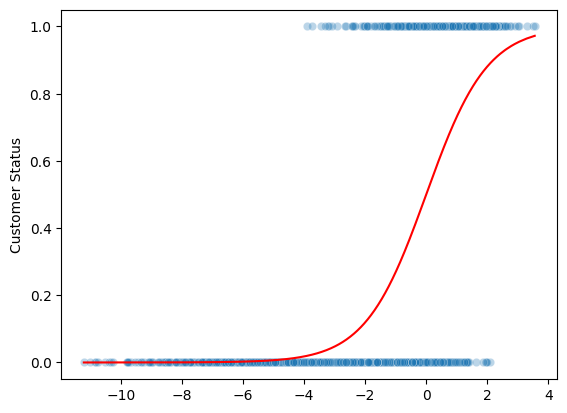

In [150]:
score = model.decision_function(X_test)
prob = model.predict_proba(X_test)[:, 1]  # Model's predicted probability of 1

sns.scatterplot(x=score, y=y_test, alpha=0.3)
sns.lineplot(x=score, y=prob, color="red")
plt.show()


In [155]:
from scipy.stats import loguniform
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RandomizedSearchCV

# 1. Define the model (max_iter=1000 prevents convergence warnings)
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# 2. Define hyperparameter options to test randomly
param_dist = {
    "C": loguniform(0.001, 100),  # Regularization strength
    "solver": ["lbfgs", "liblinear", "saga"],
    "class_weight": [None, "balanced"],  # Helps handle imbalanced churn data
}

# 3. Run RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist,
    n_iter=20,  # Tests 20 random combinations
    cv=5,  # 5-fold cross-validation
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
)
random_search.fit(X_train, y_train)

# 4. Get the best model and check accuracy
best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)
print("Best CV Accuracy:", round(random_search.best_score_, 4))

y_pred = best_model.predict(X_test)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))


Best Parameters: {'C': np.float64(0.19069966103000435), 'class_weight': None, 'solver': 'liblinear'}
Best CV Accuracy: 0.8566
Test Accuracy: 0.8558


In [156]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

[[854  81]
 [109 274]]
              precision    recall  f1-score   support

      Stayed       0.89      0.91      0.90       935
     Churned       0.77      0.72      0.74       383

    accuracy                           0.86      1318
   macro avg       0.83      0.81      0.82      1318
weighted avg       0.85      0.86      0.85      1318



In [158]:
import joblib
joblib.dump({"model": best_model, "scaler": scaler}, "churn_pipeline.joblib")
# Later, load them back to predict on new data
saved = joblib.load("churn_pipeline.joblib")
loaded_model = saved["model"]
loaded_scaler = saved["scaler"]


In [159]:
saved

{'model': LogisticRegression(C=np.float64(0.19069966103000435), max_iter=1000,
                    random_state=42, solver='liblinear'),
 'scaler': StandardScaler()}